# 04.2 Naive Bayes: búsqueda de hiperparámetros (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: `best_params/`, `trials/` y `figures/` de este modelo (cada archivo está explicado en `README.md`)

Instrucciones:

- La búsqueda usa Optuna con `N_TRIALS` pruebas y la misma validación en todos los modelos: 5 grupos separados por animal y la semilla `SEED`.
- Nombre de los archivos que se generan: `nb_clf`. Es el primer argumento de `tune(...)`, y el notebook de modelado lo usa en `load_best(...)`.
- Se hace con `tune(...)` de `tuning.py`. Solo hay que definir `make_pipe` (el pipeline) y `space` (qué ajustes se prueban y en qué rango).
- Si cambian las variables o los datos, hay que repetir la búsqueda. El notebook de modelado lo comprueba.
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, NUMERIC_LOG, add_age_log, build_preprocessor
from tuning import tune

N_TRIALS = 20

data = add_age_log(pd.read_csv("../../data/processed/dev_features.csv"))
groups = data["animal_id_intake"]

c:\Users\MAURO\Desktop\GIT\mucsi-ml-animal-shelter-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

Frente al exp 1,agregamos las variables numéricas usando KBinsDiscretizer o simplemente
mantenemos CAT_LOW + CAT_HIGH + BINARY ya que MultinomialNB no maneja bien continuas negativas.
Si el preprocesador de features.py escala las numéricas (StandardScaler, que crea negativos),
MultinomialNB fallará. Por seguridad, mantenemos solo categóricas y binarias.

In [2]:
FEATURES_EXP2_CLF = CAT_LOW + CAT_HIGH + BINARY + NUMERIC

print("El experimento 2 usa estas variables:")
print("Clasificación:", FEATURES_EXP2_CLF)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

El experimento 2 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']


# Qué se ajusta

| Ajuste | Qué hace | Rango probado |
|---|---|---|
| `alpha` | Parámetro de suavizado (Laplace/Lidstone). Evita que el modelo asigne probabilidad cero a categorías raras. | 0,0001 a 10 |

`alpha` se prueba en escala logarítmica: así se exploran por igual valores pequeños y grandes.

## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas. Se elige por macro-F1. Se elige por macro-F1. La búsqueda usa el 20 % de los animales para que cada prueba sea rápida.

Búsqueda de Naive Bayes (clasificación): 20 pruebas con 63,681 filas y 57,564 animales.
Prueba 1/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 2/20: resultado 0.443 | mejor hasta ahora 0.444
Prueba 3/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 4/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 5/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 6/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 7/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 8/20: resultado 0.443 | mejor hasta ahora 0.444
Prueba 9/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 10/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 11/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 12/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 13/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 14/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 15/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 16/20: resultado 0.444 | mejor hasta ahora 0.444
Prueba 17/20: resultado 0

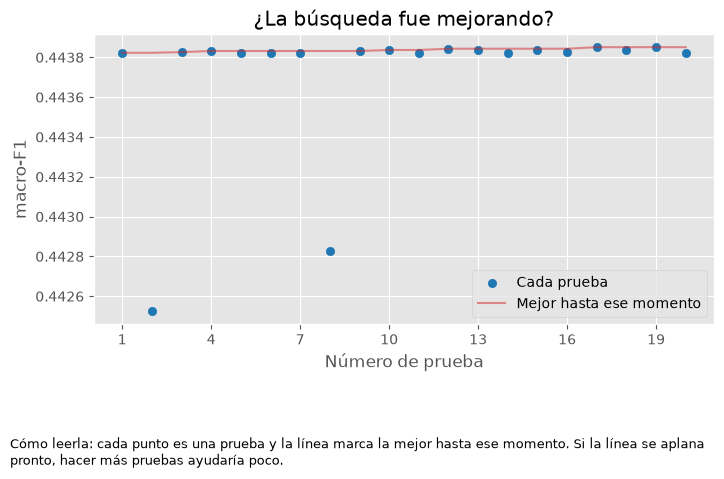

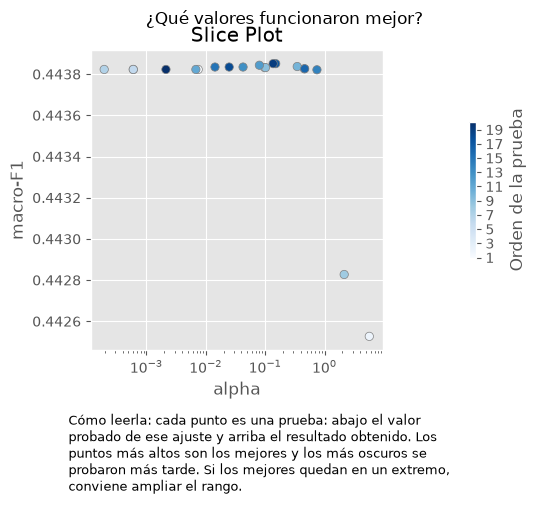

In [3]:

## 1. Clasificación

# Objetivo: y_outcome (5 clases), con todas las filas. Se elige por macro-F1.
from sklearn.preprocessing import MinMaxScaler
def make_pipe_clf(params):
    return Pipeline([
        ("prep", build_preprocessor(
            columns=FEATURES_EXP2_CLF,
            numeric_scaler=MinMaxScaler()
        )),
        ("model", MultinomialNB(**params))
    ])

def space_clf(trial):
    return {"alpha": trial.suggest_float("alpha", 1e-4, 10.0, log=True)}

study_clf = tune(
    "nb_clf", make_pipe_clf, space_clf, data[FEATURES_EXP2_CLF], y_clf, groups,
    scoring="f1_macro", features=FEATURES_EXP2_CLF, model_label="Naive Bayes", task_label="clasificación",
    params_help={"alpha": "Parámetro de suavizado. Evita probabilidades cero en categorías raras."},
    n_trials=N_TRIALS)

Naive Bayes solo clasifica: este notebook no tiene regresión.